In [28]:
ROLL_NO = 1024170103
NAME = "Pehal"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

In [29]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

In [30]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170103   Name: Pehal   Fingerprint: 3A231F79   Tickets: 15

Ticket_ID                                                                                            Ticket_Text
      T01                                             The Python is showing an error. I don't know what changed.
      T02 I keep getting logged out of the Python before the assignment deadline. The same problem occurs again.
      T03                   Projector crashes while opening while uploading the file. I don't know what changed.
      T04                                            Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T05                                                                          Version 2.0.1 crashes at 99%.
      T06                                                      The laptop stopped responding. Please resolve it.
      T07              I am unable to use the laptop when connected to campus Wi-Fi. I have tried several times!
      T08          

In [31]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

In [32]:
#Q1
processed = {}
rows = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    r = process_ticket(text)
    processed[tid] = r
    rows.append([tid, len(r["sentences"]), len(r["tokens"]), len(r["punct"]),
                 len(r["stops"]), len(set(r["tokens"])), len(r["final"])])

q1 = pd.DataFrame(rows, columns=["Ticket_ID", "sentences", "tokens", "punct_tokens",
                                 "stopwords", "unique_tokens", "final_tokens"])
total = ["TOTAL"] + list(q1.iloc[:, 1:].sum())
q1.loc[len(q1)] = total
print(q1.to_string(index=False))

Ticket_ID  sentences  tokens  punct_tokens  stopwords  unique_tokens  final_tokens
      T01          2      14             2          6             13             6
      T02          2      19             2          9             16             8
      T03          2      16             2          6             14             8
      T04          1       9             2          2              9             5
      T05          1       7             2          1              7             4
      T06          2       9             2          2              8             5
      T07          2      19             2          8             17             9
      T08          2      10             2          3              9             5
      T09          2      17             2          7             15             8
      T10          1      10             2          4              9             4
      T11          2      18             2          8             16             8
    

In [33]:
#Q1
sel = FOCUS[0]
print(sel, "-", df.loc[df["Ticket_ID"] == sel, "Ticket_Text"].values[0])
print("tokens:", processed[sel]["tokens"])
print("punctuation:", processed[sel]["punct"])
print("stopwords:", processed[sel]["stops"])
print("final tokens:", processed[sel]["final"])

T10 - The Wi-Fi works, but the VPN doesn't.
tokens: ['the', 'wi-fi', 'works', ',', 'but', 'the', 'vpn', 'does', "n't", '.']
punctuation: [',', '.']
stopwords: ['the', 'but', 'the', 'does']
final tokens: ['wi-fi', 'works', 'vpn', "n't"]


In [34]:
#Q1
odd = sorted(set(t for r in processed.values() for t in r["final"] if not t.isalpha()))
print("final tokens that are not real words:", odd)
for tid, r in processed.items():
    for t in r["final"]:
        if t in ("n't", "'s", "ca", "wo", "'m", "'ve"):
            print(tid, t)
print("word_tokenize splits contractions like doesn't into does + n't, and urls and emails into pieces, so these leftovers survive as final tokens")

final tokens that are not real words: ['2.0.1', '99', 'it.helpdesk', "n't", 'thapar.edu', 'wi-fi', 'www.thapar.edu/it']
T01 n't
T03 n't
T09 n't
T10 n't
T11 n't
T12 n't
T15 n't
word_tokenize splits contractions like doesn't into does + n't, and urls and emails into pieces, so these leftovers survive as final tokens


In [35]:
#Q2
import re

raw = " ".join(df["Ticket_Text"])

long_words = re.findall(r"\b[A-Za-z]{6,}\b", raw)
numbers = re.findall(r"\d+(?:[.,]\d+)*", raw)
capitalized = re.findall(r"\b[A-Z][A-Za-z]*(?:-[A-Za-z]+)*\b", raw)
vowel_words = re.findall(r"\b[aeiouAEIOU][A-Za-z]*(?:-[A-Za-z]+)*\b", raw)

print("longer than 5 letters:", long_words)
print("numbers:", numbers)
print("capitalized:", capitalized)
print("starting with vowel:", vowel_words)

longer than 5 letters: ['Python', 'showing', 'changed', 'getting', 'logged', 'Python', 'before', 'assignment', 'deadline', 'problem', 'occurs', 'Projector', 'crashes', 'opening', 'uploading', 'changed', 'helpdesk', 'thapar', 'thapar', 'Version', 'crashes', 'laptop', 'stopped', 'responding', 'Please', 'resolve', 'unable', 'laptop', 'connected', 'campus', 'several', 'server', 'running', 'slowly', 'worked', 'yesterday', 'couldn', 'connect', 'laptop', 'during', 'another', 'computer', 'couldn', 'connect', 'student', 'portal', 'laptop', 'problem', 'occurs', 'locked', 'Matlab', 'uploading', 'changed', 'student', 'portal', 'disconnecting', 'problem', 'occurs', 'response', 'password', 'crashes', 'opening', 'changed']
numbers: ['2.0.1', '99']
capitalized: ['The', 'Python', 'I', 'I', 'Python', 'The', 'Projector', 'I', 'Write', 'Version', 'The', 'Please', 'I', 'Wi-Fi', 'I', 'The', 'It', 'I', 'It', 'The', 'Wi-Fi', 'VPN', 'I', 'The', 'I', 'Matlab', 'I', 'The', 'The', 'I', 'The', 'I']
starting with v

In [36]:
#Q2
email_pat = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
url_pat = r"(?:https?://|www\.)[\w\-./]*[\w/]"
phone_pat = r"(?<!\w)(?:\+\d{1,3}[\s-]?)?\d{3,5}[\s-]\d{3,5}(?:[\s-]\d{3,5})?(?!\w)"

def clean(text):
    text = re.sub(email_pat, "<EMAIL>", text)
    text = re.sub(url_pat, "<URL>", text)
    text = re.sub(phone_pat, "<PHONE>", text)
    return text

for line in TEST_LINES:
    print(line)
    print(clean(line))
    print()

for t in df["Ticket_Text"]:
    if clean(t) != t:
        print(t)
        print(clean(t))
        print()

print("test lines numbers:")
for line in TEST_LINES:
    print(re.findall(r"\d+(?:[.,]\d+)*", line))

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
Write to <EMAIL> or visit <URL>.

test lines numbers:
[]
['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
['5.30']


In [37]:
#Q2
sentence_start = 0
for t in df["Ticket_Text"]:
    for s in sent_tokenize(t):
        first = re.findall(r"\b[A-Z][A-Za-z]*(?:-[A-Za-z]+)*\b", s)
        if first and s.startswith(first[0]):
            sentence_start += 1
print(sentence_start, "of", len(capitalized), "capitalized words are capitalized only because they start a sentence")

26 of 32 capitalized words are capitalized only because they start a sentence


In [38]:
# Q3
from nltk.tokenize import RegexpTokenizer

token_pat = (r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
             r"|(?:https?://|www\.)[\w\-./]*[\w/]"
             r"|(?<!\w)(?:\+\d{1,3}[\s-]?)?\d{3,5}[\s-]\d{3,5}(?:[\s-]\d{3,5})?(?!\w)"
             r"|\d+(?:[.,]\d+)+"
             r"|[A-Za-z0-9]+(?:[-'][A-Za-z0-9]+)*"
             r"|[^\w\s]")

tk = RegexpTokenizer(token_pat)

def my_tokenize(text):
    return tk.tokenize(text)

for line in TEST_LINES:
    print(my_tokenize(line))
    print(word_tokenize(line))
    print()

['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']



In [39]:
#Q3
diff_tickets = 0
for tid, t in zip(df["Ticket_ID"], df["Ticket_Text"]):
    a = my_tokenize(t)
    b = word_tokenize(t)
    if a != b:
        diff_tickets += 1
        print(tid, t)
        print("mine:", a)
        print("nltk:", b)
        print()
print(diff_tickets, "of", len(df), "tickets tokenized differently")

T01 The Python is showing an error. I don't know what changed.
mine: ['The', 'Python', 'is', 'showing', 'an', 'error', '.', 'I', "don't", 'know', 'what', 'changed', '.']
nltk: ['The', 'Python', 'is', 'showing', 'an', 'error', '.', 'I', 'do', "n't", 'know', 'what', 'changed', '.']

T03 Projector crashes while opening while uploading the file. I don't know what changed.
mine: ['Projector', 'crashes', 'while', 'opening', 'while', 'uploading', 'the', 'file', '.', 'I', "don't", 'know', 'what', 'changed', '.']
nltk: ['Projector', 'crashes', 'while', 'opening', 'while', 'uploading', 'the', 'file', '.', 'I', 'do', "n't", 'know', 'what', 'changed', '.']

T04 Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
mine: ['Write', 'to', 'it.helpdesk@thapar.edu', 'or', 'visit', 'www.thapar.edu/it', '.']
nltk: ['Write', 'to', 'it.helpdesk', '@', 'thapar.edu', 'or', 'visit', 'www.thapar.edu/it', '.']

T09 I couldn't connect to the laptop during the lab. It works on another computer.
mine: ['I', 

In [40]:
#Q3
shown = 0
for t in TEST_LINES + list(df["Ticket_Text"]):
    a = my_tokenize(t)
    b = word_tokenize(t)
    only_mine = [x for x in a if x not in b]
    only_nltk = [x for x in b if x not in a]
    if only_mine or only_nltk:
        print(t)
        print("only in my_tokenize:", only_mine)
        print("only in word_tokenize:", only_nltk)
        print()
        shown += 1
    if shown == 6:
        break

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
only in my_tokenize: ['it.helpdesk@thapar.edu', 'a.b-c@dept.univ.ac.in', 'https://lms.thapar.edu/help']
only in word_tokenize: ['it.helpdesk', '@', 'thapar.edu', 'a.b-c', '@', 'dept.univ.ac.in', 'https', ':', '//lms.thapar.edu/help']

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
only in my_tokenize: ['+91 98765 43210']
only in word_tokenize: ['+91', '98765', '43210']

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
only in my_tokenize: ["isn't", 'p', 'm', "didn't"]
only in word_tokenize: ['is', "n't", 'p.m.', 'did', "n't"]

The Python is showing an error. I don't know what changed.
only in my_tokenize: ["don't"]
only in word_tokenize: ['do', "n't"]

Projector crashes while opening while uploading the file. I don't know what changed.
only in my_tokenize: ["don't"]
only in word_tokenize: ['do', "n't"]

Wr

In [41]:
#Q4
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

unique_final = sorted(set(t for r in processed.values() for t in r["final"]))
print(len(unique_final), "unique final tokens")

ing_words = [w for w in unique_final if w.endswith("ing")]
ed_words = [w for w in unique_final if w.endswith("ed")]
s_words = [w for w in unique_final if w.endswith("s")]
print("words ending in ing:", ing_words)
print("words ending in ed:", ed_words)
print("words ending in s:", s_words)

60 unique final tokens
words ending in ing: ['disconnecting', 'getting', 'opening', 'responding', 'running', 'showing', 'uploading']
words ending in ed: ['changed', 'connected', 'locked', 'logged', 'stopped', 'tried', 'worked']
words ending in s: ['campus', 'crashes', 'keeps', 'occurs', 'times', 'works']


In [42]:
#Q4
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(r"ing$|ed$|s$", min=4)
lemmatizer = WordNetLemmatizer()

def wn_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

pos_of = {}
for r in processed.values():
    tagged = pos_tag(r["tokens"])
    for w, tag in tagged:
        if w in unique_final and w not in pos_of:
            pos_of[w] = wn_pos(tag)

rows = []
for w in unique_final:
    rows.append([w, porter.stem(w), lancaster.stem(w), regexp.stem(w),
                 lemmatizer.lemmatize(w, pos_of.get(w, wordnet.NOUN))])
stem_df = pd.DataFrame(rows, columns=["word", "porter", "lancaster", "regexp", "lemma"])
differ = stem_df[stem_df.iloc[:, 1:].nunique(axis=1) > 1]
print(differ.to_string(index=False))

      word    porter lancaster     regexp      lemma
   another     anoth     anoth    another    another
assignment    assign    assign assignment assignment
    campus     campu      camp      campu     campus
   changed     chang     chang      chang     change
  computer    comput    comput   computer   computer
   crashes     crash     crash     crashe      crash
  deadline   deadlin   deadlin   deadline   deadline
     error     error        er      error      error
      file      file       fil       file       file
   getting       get       get       gett        get
    logged       log       log       logg        log
    occurs     occur       occ      occur      occur
   opening      open        op       open       open
    please     pleas     pleas     please     please
    portal    portal      port     portal     portal
 projector projector   project  projector  projector
   resolve    resolv    resolv    resolve    resolve
  response   respons   respons   response   re

In [43]:
#q4
print("suffix rule used: ing$|ed$|s$")
for w in ing_words[:3] + ed_words[:3] + s_words[:3]:
    print(w, "->", regexp.stem(w))
print("chosen because my tickets have several words ending in ing, ed and s, like the ones above, and cutting these gives the base word for most of them")
print("it fails on doubled letters like getting -> gett and running -> runn")

suffix rule used: ing$|ed$|s$
disconnecting -> disconnect
getting -> gett
opening -> open
changed -> chang
connected -> connect
locked -> lock
campus -> campu
crashes -> crashe
keeps -> keep
chosen because my tickets have several words ending in ing, ed and s, like the ones above, and cutting these gives the base word for most of them
it fails on doubled letters like getting -> gett and running -> runn


In [44]:
#Q4
by_lemma = stem_df.groupby("lemma")
under = []
for lem, g in by_lemma:
    if g["porter"].nunique() > 1:
        under.append((lem, list(g["word"]), list(g["porter"])))
pairs = []
for a in unique_final:
    for b in unique_final:
        if a != b and len(b) >= 5 and b in a and porter.stem(a) != porter.stem(b):
            pairs.append((a, porter.stem(a), b, porter.stem(b)))
print("under-stemming (related words, different porter stems):", pairs[:3])

by_stem = stem_df.groupby("porter")
over = []
for st, g in by_stem:
    if g["lemma"].nunique() > 1:
        over.append((st, list(g["word"])))
print("over-stemming (different lemmas, same porter stem):", over[:3])

short = stem_df.assign(n=stem_df["lancaster"].str.len() / stem_df["word"].str.len()).sort_values("n").head(3)
print("lancaster cuts the most:")
print(short[["word", "porter", "lancaster", "lemma"]].to_string(index=False))

under-stemming (related words, different porter stems): [('disconnecting', 'disconnect', 'connect', 'connect'), ('www.thapar.edu/it', 'www.thapar.edu/it', 'thapar.edu', 'thapar.edu')]
over-stemming (different lemmas, same porter stem): []
lancaster cuts the most:
   word porter lancaster  lemma
opening   open        op   open
 unable  unabl        un unable
  error  error        er  error


In [45]:
#Q4
print("over-stemming: lancaster cuts opening -> op and unable -> un, which loses the meaning of the word")
print("under-stemming: disconnecting -> disconnect but connected -> connect, related words end up with different stems")

over-stemming: lancaster cuts opening -> op and unable -> un, which loses the meaning of the word
under-stemming: disconnecting -> disconnect but connected -> connect, related words end up with different stems


In [46]:
# Q5
from collections import Counter
import math
import matplotlib.pyplot as plt

S1 = [t for r in processed.values() for t in r["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for r in processed.values() for t in r["final"]]
S4 = [porter.stem(t) for t in S3]

stats = []
for name, s in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    stats.append([name, len(s), len(set(s)), round(len(set(s)) / len(s), 4)])
stats_df = pd.DataFrame(stats, columns=["set", "total_tokens", "unique_tokens", "TTR"])
print(stats_df.to_string(index=False))

set  total_tokens  unique_tokens    TTR
 S1           202             92 0.4554
 S2           170             86 0.5059
 S3            92             60 0.6522
 S4            92             57 0.6196


In [47]:
#Q5
print("top 10 S1:", Counter(S1).most_common(10))
print("top 10 S3:", Counter(S3).most_common(10))

top 10 S1: [('.', 24), ('the', 19), ('i', 11), ("n't", 7), ('to', 5), ('do', 4), ('know', 4), ('what', 4), ('changed', 4), ('again', 4)]
top 10 S3: [("n't", 7), ('know', 4), ('changed', 4), ('laptop', 4), ('problem', 3), ('occurs', 3), ('crashes', 3), ('python', 2), ('opening', 2), ('uploading', 2)]


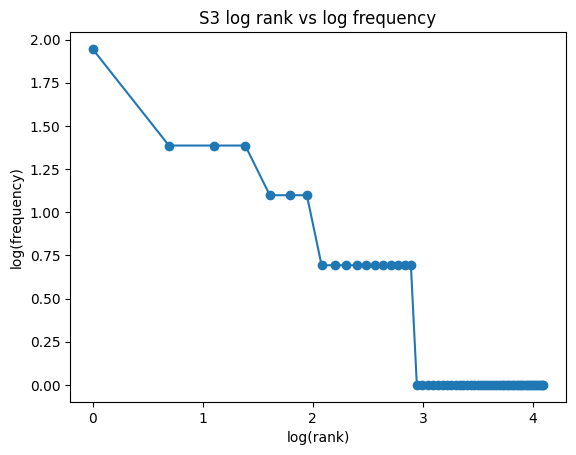

In [48]:
#Q5
freq = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(freq) + 1)
plt.plot([math.log(r) for r in ranks], [math.log(f) for f in freq], marker="o")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3 log rank vs log frequency")
plt.show()

In [49]:
#Q5
from nltk import bigrams

b1 = Counter()
b3 = Counter()
for r in processed.values():
    b1.update(bigrams(r["tokens"]))
    b3.update(bigrams(r["final"]))
print("top 5 bigrams S1:", b1.most_common(5))
print("top 5 bigrams S3:", b3.most_common(5))

top 5 bigrams S1: [(('.', 'i'), 5), (('i', 'do'), 4), (('do', "n't"), 4), (("n't", 'know'), 4), (('know', 'what'), 4)]
top 5 bigrams S3: [(("n't", 'know'), 4), (('know', 'changed'), 4), (('problem', 'occurs'), 3), (('crashes', 'opening'), 2), (('uploading', 'file'), 2)]


In [50]:
#Q5
t = stats_df.set_index("set")["TTR"]
print("TTR:", dict(t))
print("S1 has many repeated punctuation tokens and stopwords, so removing them (S2, S3) changes total tokens a lot while unique tokens drop less")
print("S4 only merges word forms with the same stem, so unique tokens fall a bit and TTR drops from S3 to S4")

TTR: {'S1': np.float64(0.4554), 'S2': np.float64(0.5059), 'S3': np.float64(0.6522), 'S4': np.float64(0.6196)}
S1 has many repeated punctuation tokens and stopwords, so removing them (S2, S3) changes total tokens a lot while unique tokens drop less
S4 only merges word forms with the same stem, so unique tokens fall a bit and TTR drops from S3 to S4


In [51]:
#Q6 a
print("TTR S1 to S4:", list(stats_df["TTR"]))
print("S1 to S3 total tokens drop from", len(S1), "to", len(S3), "because punctuation and stopwords are removed")
print("S3 to S4 unique tokens go from", len(set(S3)), "to", len(set(S4)), "because stemming merges forms of the same word")

TTR S1 to S4: [0.4554, 0.5059, 0.6522, 0.6196]
S1 to S3 total tokens drop from 202 to 92 because punctuation and stopwords are removed
S3 to S4 unique tokens go from 60 to 57 because stemming merges forms of the same word


In [52]:
#Q6 b
for t in TEST_LINES + list(df["Ticket_Text"]):
    a = my_tokenize(t)
    b = word_tokenize(t)
    if a != b:
        print(t)
        print("mine:", [x for x in a if x not in b])
        print("nltk:", [x for x in b if x not in a])
        break
print("my tokenizer keeps emails urls phone numbers and hyphenated words whole, word_tokenize splits them at punctuation")

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
mine: ['it.helpdesk@thapar.edu', 'a.b-c@dept.univ.ac.in', 'https://lms.thapar.edu/help']
nltk: ['it.helpdesk', '@', 'thapar.edu', 'a.b-c', '@', 'dept.univ.ac.in', 'https', ':', '//lms.thapar.edu/help']
my tokenizer keeps emails urls phone numbers and hyphenated words whole, word_tokenize splits them at punctuation


In [53]:
#Q6 c
for w, p in zip(stem_df["word"], stem_df["porter"]):
    if not wordnet.synsets(p) and p != w:
        print(w, "->", p)
        break
print("the stem is not a real word, so it is hard to read and can clash with other words")

another -> anoth
the stem is not a real word, so it is hard to read and can clash with other words


In [54]:
#Q6 d
for w, p, l in zip(stem_df["word"], stem_df["porter"], stem_df["lemma"]):
    if p != l and wordnet.synsets(l) and not wordnet.synsets(p):
        print(w, "-> stem:", p, "| lemma:", l)
        break
print("the lemma stays a real dictionary word with the right meaning, the stem does not")

another -> stem: anoth | lemma: another
the lemma stays a real dictionary word with the right meaning, the stem does not
